# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Visualization Settings
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


# Loading Dataset

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Dataset Information

In [4]:
print("Dataset Information:")
df.info()
print()
print("______________________________________")

print("\nColumn Names:")
print(df.columns.tolist())
print()
print("______________________________________")

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

______________________________________

Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

______________________________________

Dataset Shape:
(150, 5)


# Check Missing Values

In [5]:
missing_values = df.isnull().sum()

print("Missing Values per Column:")
display(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values per Column:


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


Total Missing Values: 0


In [6]:
# Statistical Summary

df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Analyze Target Class Distribution

Species Distribution:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

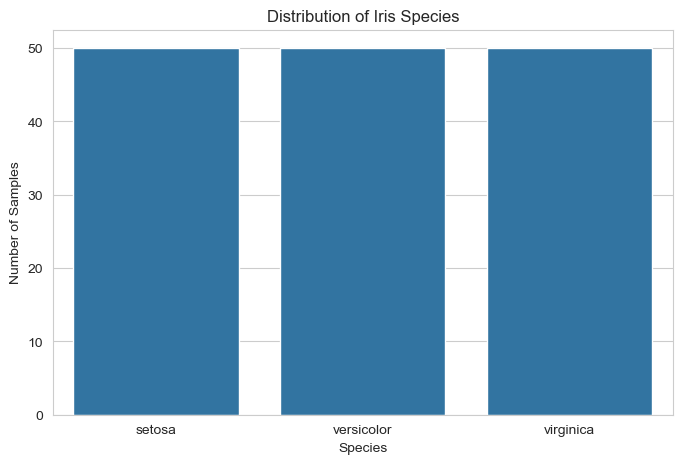

In [7]:
print("Species Distribution:")
display(df["species"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species"
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.show()

## 2. Exploratory Data Analysis (EDA)

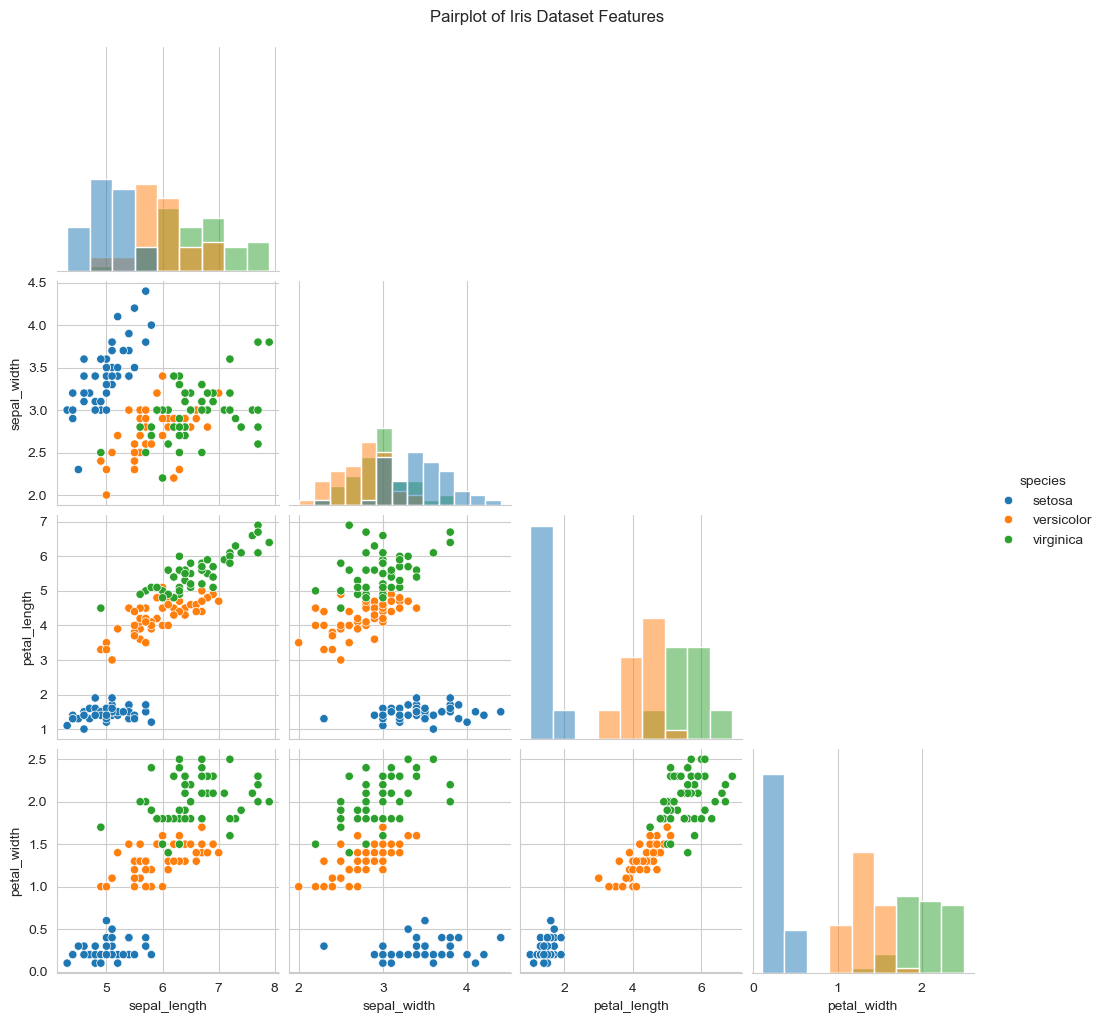

In [8]:
# Pairplot Visualization

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Pairplot of Iris Dataset Features",
    y=1.02
)

plt.show()

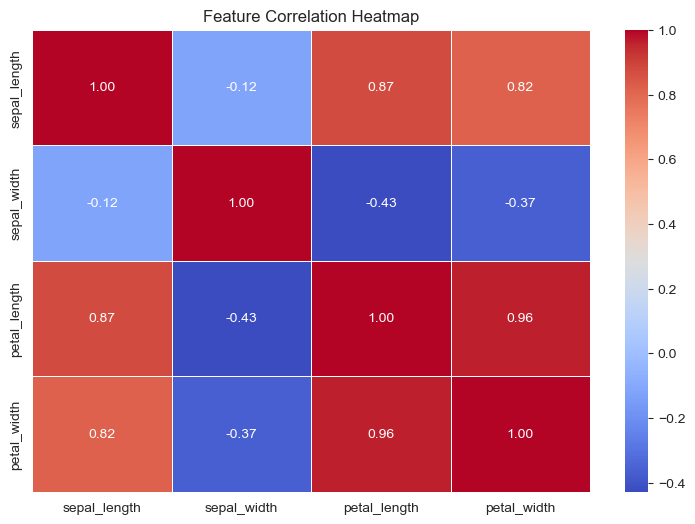

In [9]:
# Correlation Matrix

correlation_matrix = df.select_dtypes(
    include="number"
).corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.show()

## 3. Data Preprocessing

In [10]:
# Separate Features and Target

X = df.drop("species", axis=1)
y = df["species"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Names:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

Features Shape: (150, 4)
Target Shape: (150,)

Feature Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

Target Classes:
['setosa' 'versicolor' 'virginica']


#### Train-Test Split

In [11]:
# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (120, 4)
Testing Features: (30, 4)

Training Target Distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing Target Distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


#### Feature Scaling

In [12]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling completed successfully!")

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature Scaling completed successfully!
Scaled Training Shape: (120, 4)
Scaled Testing Shape: (30, 4)


## 4. Model Training


In [13]:
# Build Logistic Regression Pipeline

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the Model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [14]:
# Build Decision Tree Model

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the Model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


## 5. Model Evaluation


In [15]:
# Generate Predictions

y_pred_logistic = logistic_model.predict(X_test)

y_pred_tree = decision_tree_model.predict(X_test)

print("Predictions generated successfully!")

print("\nLogistic Regression Predictions:")
print(y_pred_logistic[:10])

print("\nDecision Tree Predictions:")
print(y_pred_tree[:10])

Predictions generated successfully!

Logistic Regression Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']

Decision Tree Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


### Logistic Regression Metrics

In [16]:
# Logistic Regression Evaluation

logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

logistic_precision = precision_score(
    y_test, y_pred_logistic, average="weighted"
)

logistic_recall = recall_score(
    y_test, y_pred_logistic, average="weighted"
)

logistic_f1 = f1_score(
    y_test, y_pred_logistic, average="weighted"
)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-Score:  {logistic_f1:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-Score:  0.9333


### Decision Tree Metrics

In [17]:
# Decision Tree Evaluation

tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_precision = precision_score(
    y_test, y_pred_tree, average="weighted"
)

tree_recall = recall_score(
    y_test, y_pred_tree, average="weighted"
)

tree_f1 = f1_score(
    y_test, y_pred_tree, average="weighted"
)

print("Decision Tree Performance")
print("--------------------------------")
print(f"Accuracy:  {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall:    {tree_recall:.4f}")
print(f"F1-Score:  {tree_f1:.4f}")

Decision Tree Performance
--------------------------------
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
F1-Score:  0.9333


## Classification Reports

In [18]:
# Logistic Regression Classification Report

print("Logistic Regression Classification Report")
print(classification_report(y_test, y_pred_logistic))

# Decision Tree Classification Report

print("\nDecision Tree Classification Report")
print(classification_report(y_test, y_pred_tree))

Logistic Regression Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 6. Confusion Matrix Analysis


#### Logistic Regression Confusion Matrix


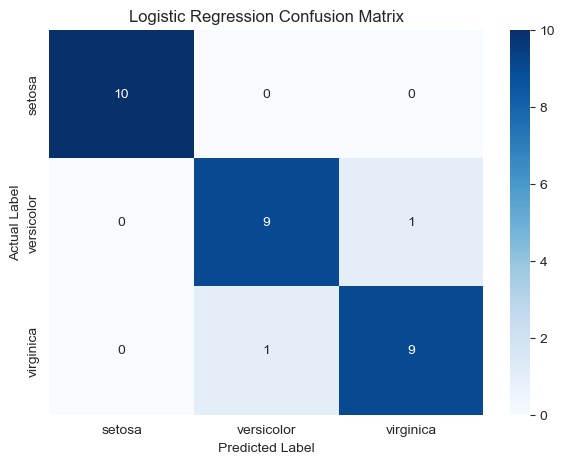

In [19]:
# Logistic Regression Confusion Matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=logistic_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=logistic_model.classes_,
    yticklabels=logistic_model.classes_
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

#### Decision Tree Confusion Matrix


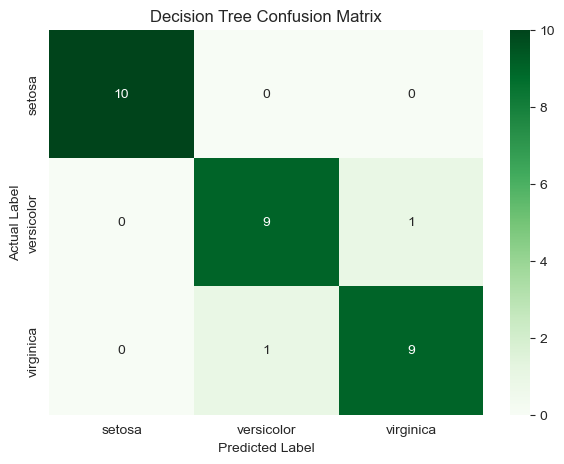

In [20]:
# Decision Tree Confusion Matrix

cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=decision_tree_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=decision_tree_model.classes_,
    yticklabels=decision_tree_model.classes_
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

## 7. Model Comparison


In [21]:
# Create Model Comparison DataFrame

comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logistic_accuracy, tree_accuracy],
    "Precision": [logistic_precision, tree_precision],
    "Recall": [logistic_recall, tree_recall],
    "F1-Score": [logistic_f1, tree_f1]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333


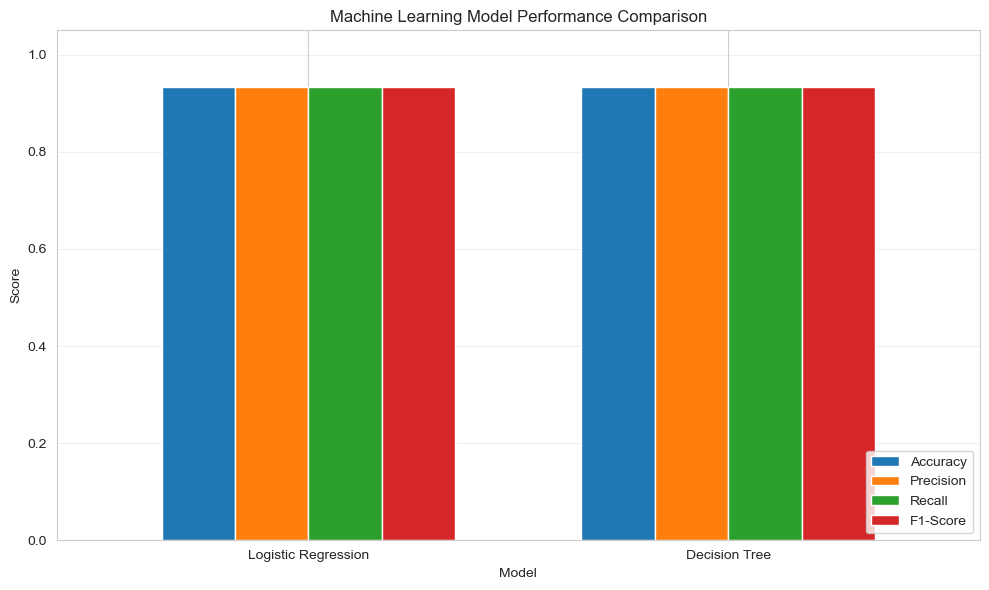

In [22]:
# Model Performance Comparison Chart

comparison_plot = comparison_df.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05),
    width=0.7
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Final Conclusion

In this project, we developed and evaluated two supervised machine learning classification models using the Iris dataset.

The models were:
- Logistic Regression
- Decision Tree Classifier

### Key Findings

- The dataset contains 150 samples and four numerical features.
- The dataset has three balanced target classes.
- The data was split into 80% training and 20% testing.
- Feature scaling was applied using StandardScaler within a Pipeline for Logistic Regression.
- Both models achieved an accuracy of 93.33%.
- Both models achieved identical Precision, Recall, and F1-Score values.

### Final Result

Both models demonstrated strong classification performance.

Since both models achieved identical evaluation scores, neither model showed a performance advantage on this test split.

Further evaluation using cross-validation could provide a more reliable comparison.

In [23]:
# Final Results Summary

print("=" * 55)
print("FINAL PROJECT RESULTS")
print("=" * 55)

print(f"Dataset Samples: {len(df)}")
print(f"Number of Features: {X.shape[1]}")
print(f"Training Samples: {len(X_train)}")
print(f"Testing Samples: {len(X_test)}")

print("\nLogistic Regression Accuracy:",
      f"{logistic_accuracy * 100:.2f}%")

print("Decision Tree Accuracy:",
      f"{tree_accuracy * 100:.2f}%")

print("\nProject Completed Successfully!")
print("=" * 55)

FINAL PROJECT RESULTS
Dataset Samples: 150
Number of Features: 4
Training Samples: 120
Testing Samples: 30

Logistic Regression Accuracy: 93.33%
Decision Tree Accuracy: 93.33%

Project Completed Successfully!
